In [2]:
import pickle
import re
import warnings

warnings.filterwarnings('ignore')

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import confusion_matrix

import myutils


In [3]:
workspace,experiment=myutils.workspace()
IS_FINE_TUNED = True
run = "pred_ms-2026-10-14_132744"
run = "pred_pbmc3k-2026-10-21_122719"
run = "pred_pbmc3k-2026-10-13_133425"
run = "pred_heroes-2026-10-25_172348"
save = True

In [4]:
match = re.match(r'pred_(.+?)-(.+)_.*',run)
dataset = match.group(1)
pred = 'pred-with-fine-tuning' if IS_FINE_TUNED else 'pred-wo-fine-tuning'
pred_dir = experiment / f'results/{pred}/{run}'
result_file = pred_dir / 'results.pkl'
assert pred_dir.exists()
assert result_file.exists()

if (dataset == "pbmc3k"):
    data_file = data_dir = experiment/ "data/pbmc3k_scanpy_annotated_batches.h5ad"
    celltype_col = "celltype"
if (dataset == "ms"):
    data_file = workspace / "data/ms/ms_batches.h5ad"
    celltype_col = "celltype"
if (dataset == "heroes"):
    data_file = experiment / "data/hereos_pool7_scRNA_batches_hvg.h5ad"
    celltype_col = "consensus_celltype"

assert data_file.exists()

In [5]:
with open(result_file, 'rb') as f:
    results = pickle.load(f)
id2type = results['id_maps']
predictions = results['predictions']
labels = results['labels']

adata = sc.read(data_file)

In [6]:
adata_test = adata[adata.obs.str_batch == '1']
adata_test.obs["predictions"] = [id2type[p] for p in predictions]

# if 'X_umap' not in adata_test.obsm and 'umap' not in adata_test.obsm:
#     sc.pp.neighbors(adata_test, n_neighbors=20, n_pcs=30)
#     sc.tl.umap(adata_test)

In [7]:
sum(adata_test.obs[celltype_col] == adata_test.obs['predictions'])

7663

In [8]:
sc.pl.umap(
        adata_test,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata_test.obs[celltype_col].cat.categories,
        adata_test.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

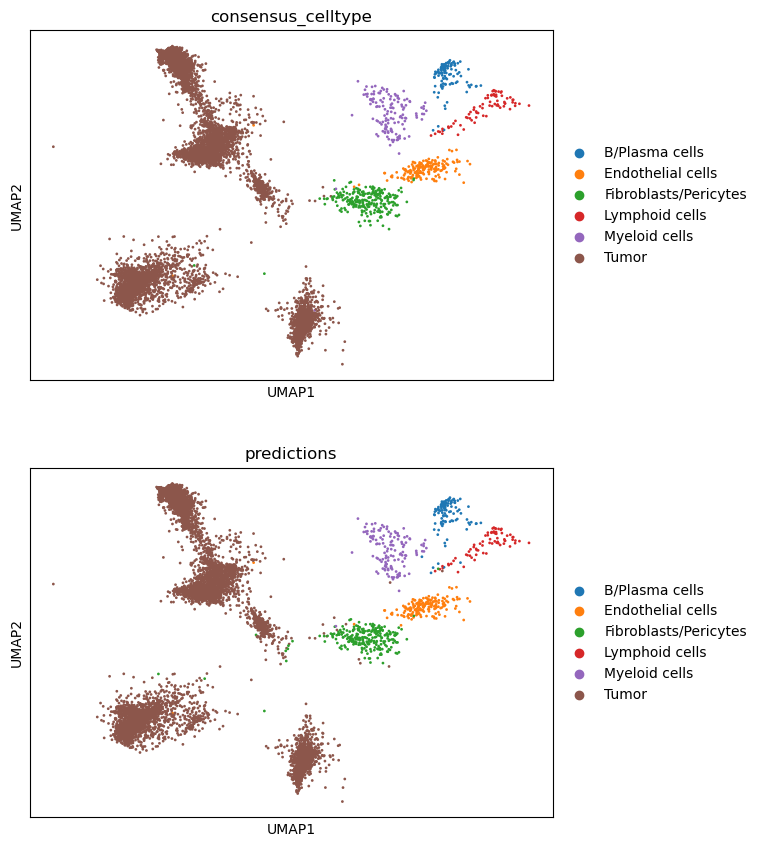

In [9]:
sc.pl.umap(
        adata_test,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
if save: plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")

In [10]:
# myutils.inspect_prediction(adata_test, 'oligodendrocyte C', palette=_palette)
# myutils.inspect_prediction(adata_test, 'phagocyte', palette=_palette)

In [11]:
# myutils.select_celltype(adata_test, 'phagocyte', palette=_palette)
# myutils.select_prediction(adata_test, 'phagocyte', palette=_palette)

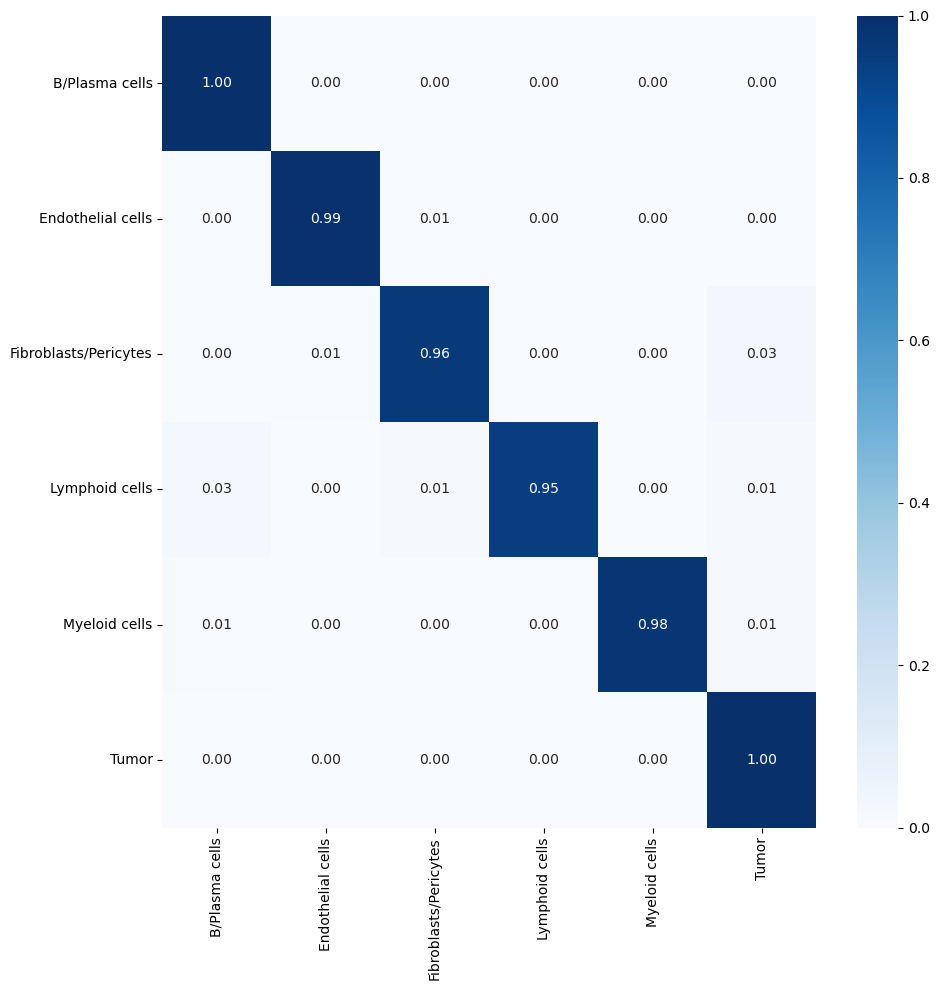

In [15]:
celltypes = adata.obs[celltype_col].unique()
celltypes = [id2type[i] for i in range(len(celltypes))]
for i in {id2type[p] for p in predictions}:
    if i not in celltypes:
        celltypes.remove(i)
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])

plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.yticks(rotation=0)
plt.tight_layout()
if save: plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )

In [13]:
cm

,B/Plasma cells,Endothelial cells,Fibroblasts/Pericytes,Lymphoid cells,Myeloid cells,Tumor
B/Plasma cells,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Endothelial cells,0.000000,0.994318,0.005682,0.000000,0.000000,0.000000
Fibroblasts/Pericytes,0.000000,0.011583,0.957529,0.000000,0.000000,0.030888
Lymphoid cells,0.026667,0.000000,0.013333,0.946667,0.000000,0.013333
Myeloid cells,0.007299,0.000000,0.000000,0.000000,0.978102,0.014599
Tumor,0.000000,0.000000,0.001298,0.000000,0.000000,0.998702
